In [1]:
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

Define LLM

In [17]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0,
)

In [18]:
from langgraph.graph import StateGraph,START, END
from typing import TypedDict


create a state

In [19]:
class LLMState(TypedDict):
    question:str 
    answer:str

creating node

In [20]:
def llm_qa(state:LLMState)->LLMState:

    #extract question from state
    question=state['question']

    prompt=f'Answer the following question {question}'

    answer=model.invoke(prompt)

    state['answer']=answer

    return state

Creating Graph

In [21]:
graph=StateGraph(LLMState)
#add nodes
graph.add_node('llm_qa',llm_qa)

#add edges
graph.add_edge(START,'llm_qa')
graph.add_edge('llm_qa',END)

#compile 
workflow=graph.compile()


Execute Graph

In [22]:
initial_state={'question':'what is photosyntesis?'}

final_state=workflow.invoke(initial_state)

print(final_state['answer'])

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


content=[{'type': 'text', 'text': '**Photosynthesis** is the process used by plants, algae, and some bacteria to convert sunlight into usable chemical energy. \n\nIn simple terms, it is how plants make their own food. \n\nHere is how it works:\nPlants take in three main ingredients from their environment:\n1. **Sunlight** (absorbed by a green pigment called *chlorophyll* in their leaves).\n2. **Carbon dioxide** (absorbed from the air through tiny pores in the leaves).\n3. **Water** (absorbed from the soil through the roots).\n\nInside the plant cells, these ingredients undergo a chemical reaction. The plant uses the energy from the sunlight to transform the carbon dioxide and water into:\n* **Glucose (sugar):** This is the food the plant uses to grow and survive.\n* **Oxygen:** This is released back into the air as a byproduct, which is essential for humans and most other animals to breathe.\n\n**The basic equation for photosynthesis is:**\n$$\\text{Sunlight} + \\text{Carbon Dioxide} +

Visualize Graph

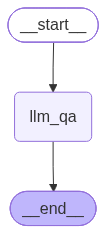

In [23]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

Prompt Chaining-> Multi LLM Call

In [24]:
class BlogState(TypedDict):
    title:str 
    outline:str
    content:str 


creating nodes

In [25]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [26]:

def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

Define and Compile Graph

In [27]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

Execute Graph

In [28]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'title': 'Rise of AI in India', 'outline': [{'type': 'text', 'text': 'Here is a comprehensive and detailed blog outline on the topic **"The Rise of AI in India: Innovation, Impact, and the Road Ahead."** \n\nThis outline is designed for a 1,500–2,000-word in-depth article targeting tech enthusiasts, business leaders, policymakers, and curious professionals.\n\n---\n\n# Blog Outline: The Rise of AI in India\n\n## I. Catchy Title Options\n*   *From Jugaad to Generative: How India is Coding its AI Future*\n*   *The Bharat AI Boom: Why India is Poised to Lead the Global Intelligence Revolution*\n*   *Decoding the Rise of AI in India: Opportunities, Challenges, and the Road Ahead*\n\n---\n\n## II. Introduction\n*   **The Hook:** Start with a relatable scenario—e.g., interacting with a regional language chatbot, a farmer using AI crop-monitoring apps, or India’s massive UPI digital backbone integrating AI.\n*   **The Big Picture:** India is no longer just a back-office IT hub; it is rapidly

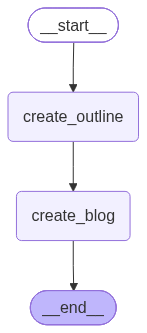

In [29]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())